# 04 — Monitoreo: drift de datos, concepto y modelo

Comparo el periodo de train (step <= 400) contra producción (step >= 401) con Evidently, PSI a mano y métricas del modelo por ventana de tiempo.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb

from evidently.legacy.metric_preset import DataDriftPreset, TargetDriftPreset
from evidently.legacy.pipeline.column_mapping import ColumnMapping
from evidently.legacy.report import Report

SEED = 42
TARGET = "isFraud"

BASE = Path.cwd()
for candidato in [BASE, *BASE.parents]:
    if (candidato / "modelos" / "modelo_xgb.json").exists():
        RUTA_BASE = candidato
        break
else:
    raise FileNotFoundError("No encontré modelos/modelo_xgb.json. Corre primero el notebook 02.")

RUTA_PROC = RUTA_BASE / "Datos" / "procesado"
RUTA_MODELOS = RUTA_BASE / "modelos"
RUTA_REPORTS = RUTA_BASE / "Reports"

FEATURES = json.loads((RUTA_PROC / "resumen_preprocesamiento.json").read_text(encoding="utf-8"))["features"]
train = pd.read_parquet(RUTA_PROC / "train.parquet")
prod = pd.read_parquet(RUTA_PROC / "prod.parquet")

booster = xgb.Booster()
booster.load_model(str(RUTA_MODELOS / "modelo_xgb.json"))

def predecir(df):
    return booster.predict(xgb.DMatrix(df[FEATURES], feature_names=FEATURES))

prod = prod.copy()
prod["prob"] = predecir(prod)
prod["pred"] = (prod["prob"] >= 0.5).astype(int)
print(f"train {train.shape} | prod {prod.shape}")

train (5787030, 14) | prod (575590, 15)


## Data drift con Evidently

In [2]:
ref = train.sample(50_000, random_state=SEED)
cur = prod.sample(50_000, random_state=SEED)

cm_data = ColumnMapping(numerical_features=FEATURES, target=None)
report_drift = Report(metrics=[DataDriftPreset()])
report_drift.run(reference_data=ref, current_data=cur, column_mapping=cm_data)
report_drift.save_html(str(RUTA_REPORTS / "evidently_data_drift.html"))
print("Reporte guardado en Reports/evidently_data_drift.html")
for nombre, tabla in report_drift.as_dataframe().items():
    print(f"--- {nombre} ---")
    print(tabla.to_string(index=False))

Reporte guardado en Reports/evidently_data_drift.html
--- DatasetDriftMetric ---
 drift_share  number_of_columns  number_of_drifted_columns  share_of_drifted_columns  dataset_drift          metric_id               metric_fingerprint
         0.5                 12                          1                  0.083333          False DatasetDriftMetric eb75be4bf9fbac23ed47059053232258
--- DataDriftTable ---
                                          type      column_name column_type                 stattest_name  stattest_threshold  drift_score  drift_detected      metric_id               metric_fingerprint
evidently:metric_result:ColumnDataDriftMetrics           amount         num Wasserstein distance (normed)                 0.1     0.031839           False DataDriftTable 8c49b4dcadf84ddd94342d386ee3f214
evidently:metric_result:ColumnDataDriftMetrics errorBalanceDest         num Wasserstein distance (normed)                 0.1     0.051439           False DataDriftTable 8c49b4dcadf84ddd

## Target drift (concept drift)

In [3]:
cm_target = ColumnMapping(numerical_features=FEATURES, target=TARGET)
report_target = Report(metrics=[TargetDriftPreset()])
report_target.run(reference_data=ref, current_data=cur, column_mapping=cm_target)
report_target.save_html(str(RUTA_REPORTS / "evidently_target_drift.html"))
print("Reporte guardado en Reports/evidently_target_drift.html")
for nombre, tabla in report_target.as_dataframe().items():
    print(f"--- {nombre} ---")
    print(tabla.to_string(index=False))

Reporte guardado en Reports/evidently_target_drift.html
--- ColumnDriftMetric ---
                                          type column_name column_type           stattest_name  stattest_threshold  drift_score  drift_detected         metric_id               metric_fingerprint
evidently:metric_result:ColumnDataDriftMetrics     isFraud         cat Jensen-Shannon distance                 0.1     0.036101           False ColumnDriftMetric c937b6c8e90acbbf1b7e2a7fc4defef7
--- ColumnCorrelationsMetric ---
Empty DataFrame
Columns: [metric_id, metric_fingerprint]
Index: []
--- TargetByFeaturesTable ---
                                                type reference target_name columns task             metric_id               metric_fingerprint
evidently:metric_result:TargetByFeaturesTableResults      None        None      []      TargetByFeaturesTable 1f004c7a2ac94f5e4f03548f759b549b


## PSI calculado a mano

In [4]:
def calcular_psi(train_s, prod_s, bins=10):
    t = train_s.dropna()
    p = prod_s.dropna()
    if t.nunique() <= 10:  # variables discretas (binarias, flags): PSI por conteo
        ct = t.value_counts(normalize=True)
        cp = p.value_counts(normalize=True)
        cats = ct.index.union(cp.index)
        tv = ct.reindex(cats, fill_value=0.0).to_numpy(dtype=float)
        pv = cp.reindex(cats, fill_value=0.0).to_numpy(dtype=float)
    else:  # variables continuas: PSI por cuantiles
        cortes = np.unique(np.quantile(t, np.linspace(0, 1, bins + 1)))
        if len(cortes) < 3:
            return 0.0
        tv = np.histogram(t, bins=cortes)[0] / len(t)
        pv = np.histogram(p, bins=cortes)[0] / len(p)
    eps = 1e-6
    tv = np.clip(tv, eps, None)
    pv = np.clip(pv, eps, None)
    return float(np.sum((pv - tv) * np.log(pv / tv)))


filas = []
for col in FEATURES:
    filas.append({"variable": col, "psi": calcular_psi(train[col], prod[col])})
filas.append({"variable": TARGET, "psi": calcular_psi(train[TARGET], prod[TARGET])})

tabla_psi = pd.DataFrame(filas).sort_values("psi", ascending=False).reset_index(drop=True)
tabla_psi["estado"] = np.select(
    [tabla_psi["psi"] < 0.1, tabla_psi["psi"] <= 0.25],
    ["estable", "alerta"],
    default="drift",
)
tabla_psi.round(4)

,variable,psi,estado
0,step,11.5133,drift
1,errorBalanceDest,0.0122,estable
2,isFraud,0.0122,estable
3,ratio_amount,0.0074,estable
4,errorBalanceOrig,0.0043,estable
5,newbalanceDest,0.0038,estable
6,oldbalanceOrg,0.0036,estable
7,amount,0.0034,estable
8,isCashOut,0.0027,estable
9,oldbalanceDest,0.0025,estable


In [5]:
tabla_psi.round(4).to_csv(RUTA_REPORTS / "psi_por_variable.csv", index=False)
print(tabla_psi.to_string(index=False))

        variable       psi  estado
            step 11.513254   drift
errorBalanceDest  0.012201 estable
         isFraud  0.012193 estable
    ratio_amount  0.007369 estable
errorBalanceOrig  0.004275 estable
  newbalanceDest  0.003809 estable
   oldbalanceOrg  0.003632 estable
          amount  0.003421 estable
       isCashOut  0.002747 estable
  oldbalanceDest  0.002497 estable
  newbalanceOrig  0.002325 estable
      isMerchant  0.000996 estable
      isTransfer  0.000492 estable


## Métricas del modelo por ventana de tiempo (model drift)

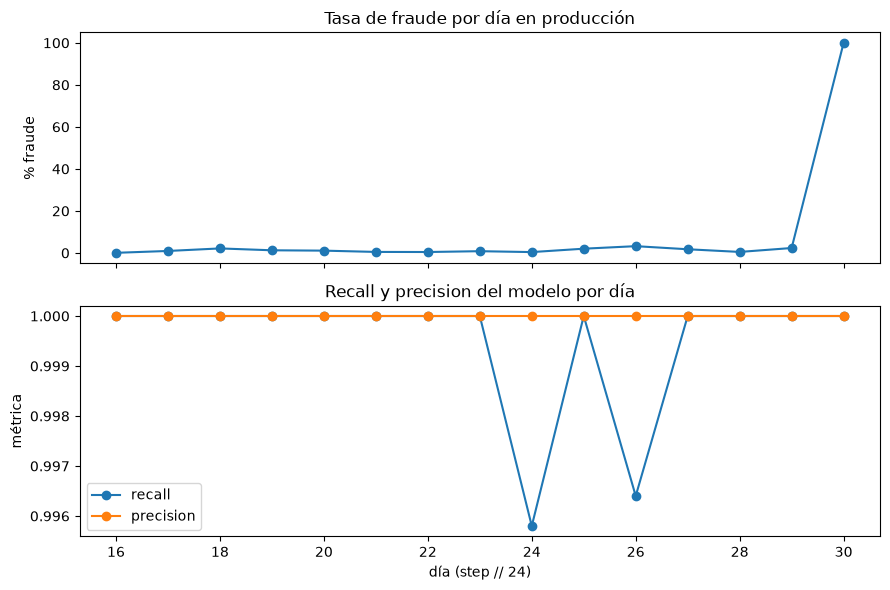

,dia,transacciones,pct_fraude,recall,precision
0,16,192131,0.0531,1.0000,1.0
1,17,29251,0.9367,1.0000,1.0
2,18,11286,2.1442,1.0000,1.0
3,19,19739,1.2564,1.0000,1.0
4,20,24589,1.0899,1.0000,1.0
5,21,52510,0.4799,1.0000,1.0
6,22,50432,0.4362,1.0000,1.0
7,23,33349,0.8276,1.0000,1.0
8,24,58712,0.4020,0.9958,1.0
9,25,13893,2.0154,1.0000,1.0


In [6]:
prod["dia"] = (prod["step"] // 24).astype(int)

filas = []
for dia, g in prod.groupby("dia"):
    tp = int(((g[TARGET] == 1) & (g["pred"] == 1)).sum())
    fn = int(((g[TARGET] == 1) & (g["pred"] == 0)).sum())
    fp = int(((g[TARGET] == 0) & (g["pred"] == 1)).sum())
    filas.append({
        "dia": dia,
        "transacciones": len(g),
        "pct_fraude": round(100 * g[TARGET].mean(), 4),
        "recall": round(tp / (tp + fn), 4) if tp + fn else np.nan,
        "precision": round(tp / (tp + fp), 4) if tp + fp else np.nan,
    })
por_dia = pd.DataFrame(filas)
por_dia.to_csv(RUTA_REPORTS / "metricas_por_dia.csv", index=False)

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(por_dia["dia"], por_dia["pct_fraude"], marker="o")
ax[0].set_ylabel("% fraude")
ax[0].set_title("Tasa de fraude por día en producción")
ax[1].plot(por_dia["dia"], por_dia["recall"], marker="o", label="recall")
ax[1].plot(por_dia["dia"], por_dia["precision"], marker="o", label="precision")
ax[1].set_ylabel("métrica")
ax[1].set_xlabel("día (step // 24)")
ax[1].set_title("Recall y precision del modelo por día")
ax[1].legend()
plt.tight_layout()
plt.show()

por_dia

In [7]:
resumen = {
    "pct_fraude_train": round(100 * float(train[TARGET].mean()), 4),
    "pct_fraude_prod": round(100 * float(prod[TARGET].mean()), 4),
    "psi": {r["variable"]: round(r["psi"], 4) for _, r in tabla_psi.iterrows()},
    "peor_dia_recall": por_dia.dropna(subset=["recall"]).sort_values("recall").head(3).to_dict(orient="records"),
}
(RUTA_REPORTS / "drift_resumen.json").write_text(json.dumps(resumen, indent=2), encoding="utf-8")
print(json.dumps(resumen, indent=2))

{
  "pct_fraude_train": 0.0774,
  "pct_fraude_prod": 0.6491,
  "psi": {
    "step": 11.5133,
    "errorBalanceDest": 0.0122,
    "isFraud": 0.0122,
    "ratio_amount": 0.0074,
    "errorBalanceOrig": 0.0043,
    "newbalanceDest": 0.0038,
    "oldbalanceOrg": 0.0036,
    "amount": 0.0034,
    "isCashOut": 0.0027,
    "oldbalanceDest": 0.0025,
    "newbalanceOrig": 0.0023,
    "isMerchant": 0.001,
    "isTransfer": 0.0005
  },
  "peor_dia_recall": [
    {
      "dia": 24,
      "transacciones": 58712,
      "pct_fraude": 0.402,
      "recall": 0.9958,
      "precision": 1.0
    },
    {
      "dia": 26,
      "transacciones": 8574,
      "pct_fraude": 3.219,
      "recall": 0.9964,
      "precision": 1.0
    },
    {
      "dia": 16,
      "transacciones": 192131,
      "pct_fraude": 0.0531,
      "recall": 1.0,
      "precision": 1.0
    }
  ]
}


## Análisis

- **Data drift (Evidently)**: de las 12 features solo `step` marca drift (Wasserstein 2.54 > 0.1); `dataset_drift=False`. Las variables de saldo y monto pasan todos los tests con distancias chicas (amount 0.032, errorBalanceOrig 0.042), o sea las entradas del modelo se comportan igual en producción que en entrenamiento.
- **PSI a mano**: coincide con Evidently. `step` da PSI 11.51, muy arriba de 0.25 — eso significa que la distribución de esa variable cambió por completo entre train y producción, y es esperado: train cubre los steps 1-400 y producción los 401-744, son ventanas de tiempo disjuntas por diseño, no un problema de los datos. Si un PSI así saliera con una variable de entrada (amount, balances) sí habría que preocuparse y reentrenar. Las demás variables quedan todas bajo 0.02 (estables).
- **Ojo con el target**: el PSI de `isFraud` da 0.0122 ("estable") porque el 99% de las filas es "no fraude" en ambos periodos y el PSI pesa proporciones; pero la tasa de fraude pasó de 0.0774% a 0.6491%, o sea se multiplicó por 8. Los tests de distribución no lo marcan, por eso reviso el concept drift por ventana.
- **Métricas por ventana (model drift)**: el recall mínimo por día en producción es 0.9958 (día 24) y la precision se mantiene en 1.0 todos los días. El modelo no se degrada ni con el fraude concentrado al final.
- Para producción quedaron armados tres sensores: los reportes HTML de Evidently, la tabla de PSI y las métricas por ventana; si el PSI de una feature pasa de 0.25 o el recall por día cae, toca reentrenar.